In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "Times New Roman"
#plt.rcParams["mathtext.fontset"] = "custom"
#plt.rcParams["mathtext.rm"] = "Times New Roman"

import matplotlib.colors as mcolors
import matplotlib as mpl

white_blue_red = mcolors.LinearSegmentedColormap.from_list(
    "white_blue_red",
    [(0, "white"), (0.5, "blue"), (1, "red")]
)

import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0,1,14))

In [2]:
def readlmpEne(filename,steps=101):
    output = []
    with open(filename,'r') as f:
        while True:
            line = f.readline()
            if not line:
                break
            else:
                if 'Step Temp PotEng KinEng E_vdwl E_coul E_bond E_angle' in line:
                    for i in range(steps):
                        line = f.readline()
                        output.append([float(x) for x in line.split()])
                        if 'Loop time of' in line:
                            break
    return np.array(output)

In [3]:
def readLMP_COMPOSITION(filename):
    decompositions = []
    with open(filename,'r') as f:
        while True:
            line = f.readline()
            if not line:
                break
            else:
                if "Excluding" in line:
                    excluding = float(line.split()[1])
                    stacking  = float(line.split()[3])
                    hb        = float(line.split()[5])

                    line = f.readline()
                    
                    coul      = float(line.split()[3])
                    vdw_add   = float(line.split()[5])
        
                    decompositions.append([excluding,stacking, hb,coul,vdw_add])

    return np.array(decompositions)

In [4]:
f_lmp_decomp = 'LMP_PRINT'
d_lmp_decomp = readLMP_COMPOSITION(f_lmp_decomp)

In [5]:
f_lmpene = 'log.lammps'
d_lmpene = readlmpEne(f_lmpene)

In [6]:
def readData(filename):
    output = []
    with open(filename,'r') as f:
        while True:
            line = f.readline()
            if not line:
                break
            else:
                if 'Step ' not in line:
                    output = [float(x) for x in line.split()]

    return output

In [7]:
enetest = []
d_lmpene = []
for i in range(0,10000001,100000):
    f_tmp = 'log.{}'.format(i)
    d_tmp = readData(f_tmp)
    enetest.append(d_tmp)

    f_lmp_tmp = 'log.lammps.{}'.format(i)
    d_lmp_tmp = list(readlmpEne(f_lmp_tmp,1))
    d_lmpene.append(d_lmp_tmp)

enetest = np.array(enetest)
d_lmpene = np.array(d_lmpene).squeeze()
print(d_lmpene.shape)

(101, 8)


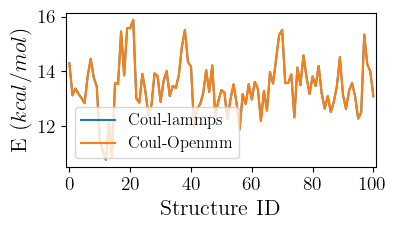

In [8]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(np.arange(d_lmpene.shape[0]), d_lmpene[:,5], label='Coul-lammps')
ax.plot(np.arange(d_lmpene.shape[0]), enetest[:,6], label='Coul-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

plt.savefig('figures/ene_coul.png', dpi=1000, bbox_inches='tight')

coul_ene_diff = d_lmpene[:,5] - enetest[:,6]
np.savetxt('coul.txt',coul_ene_diff)

Text(0.5, 1.0, 'Coul')

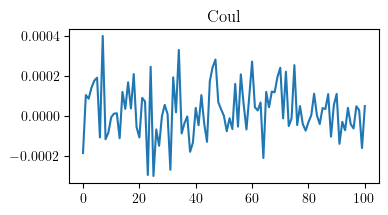

In [9]:
fig, ax = plt.subplots(figsize=(4,2))
ax.plot(np.arange(len(coul_ene_diff)),coul_ene_diff)
ax.set_title('Coul')

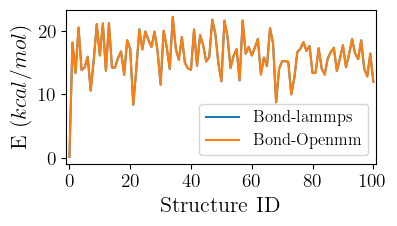

In [10]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(np.arange(d_lmpene.shape[0]), d_lmpene[:,6], label='Bond-lammps')
ax.plot(np.arange(d_lmpene.shape[0]), enetest[:,1], label='Bond-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

plt.savefig('figures/ene_bond.png', dpi=1000, bbox_inches='tight')

bond_ene_diff = d_lmpene[:,6] - enetest[:,1]
np.savetxt('bond.txt',bond_ene_diff)

Text(0.5, 1.0, 'Bond')

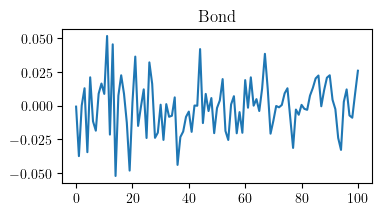

In [11]:
fig, ax = plt.subplots(figsize=(4,2))
ax.plot(np.arange(len(bond_ene_diff)),bond_ene_diff)
ax.set_title('Bond')

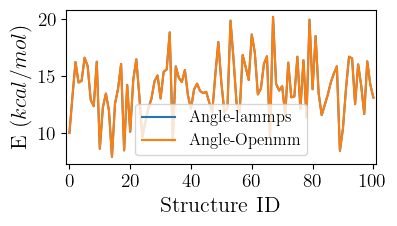

In [12]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(np.arange(d_lmpene.shape[0]), d_lmpene[:,-1], label='Angle-lammps')
ax.plot(np.arange(d_lmpene.shape[0]), enetest[:,2], label='Angle-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

plt.savefig('figures/ene_angle.png', dpi=1000, bbox_inches='tight')

angle_ene_diff = d_lmpene[:,-1] - enetest[:,2]
np.savetxt('angle.txt',angle_ene_diff)

Text(0.5, 1.0, 'Angle')

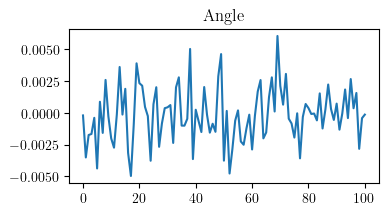

In [13]:
fig, ax = plt.subplots(figsize=(4,2))
ax.plot(np.arange(len(angle_ene_diff)),angle_ene_diff)
ax.set_title('Angle')

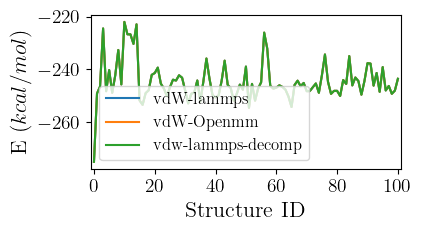

In [29]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(np.arange(d_lmpene.shape[0]), d_lmpene[:,4], label='vdW-lammps')
ax.plot(np.arange(d_lmpene.shape[0]), enetest[:,3]+enetest[:,4]+enetest[:,5]+enetest[:,7], label='vdW-Openmm')
ax.plot(np.arange(d_lmpene.shape[0]), d_lmp_decomp[:,0]+d_lmp_decomp[:,1]+d_lmp_decomp[:,2]+d_lmp_decomp[:,4], label='vdw-lammps-decomp')
#ax.scatter(d_lmpene[:,0]/10**5, enetest[:,3]+enetest[:,4]+enetest[:,5], label='vdW-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

plt.savefig('figures/ene_vdW.png', dpi=1000, bbox_inches='tight')

vdw_ene_diff = d_lmpene[:,4] - enetest[:,3] - enetest[:,4] - enetest[:,5] - enetest[:,7]
vdw_ene_diff_lmp_lmp_decomp = d_lmpene[:,4] - (d_lmp_decomp[:,0]+d_lmp_decomp[:,1]+d_lmp_decomp[:,2]+d_lmp_decomp[:,4])
#np.savetxt('vdw.txt',vdw_ene_diff)

Text(0.5, 1.0, 'vdW')

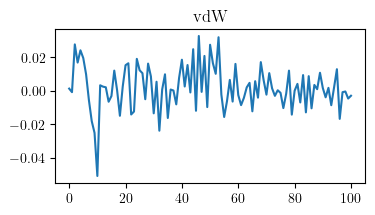

In [28]:
fig, ax = plt.subplots(figsize=(4,2))
ax.plot(np.arange(len(vdw_ene_diff)),vdw_ene_diff)
#ax.plot(np.arange(len(vdw_ene_diff_lmp_lmp_decomp)),vdw_ene_diff_lmp_lmp_decomp)
ax.set_title('vdW')

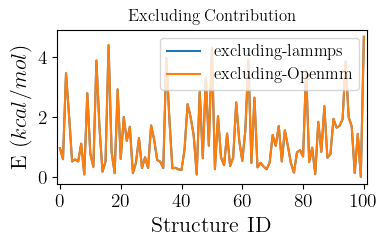

In [16]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(np.arange(d_lmp_decomp.shape[0]), d_lmp_decomp[:,0], label='excluding-lammps')
ax.plot(np.arange(d_lmp_decomp.shape[0]), enetest[:,5], label='excluding-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

ax.set_title('Excluding Contribution')

excluding_ene_diff = d_lmp_decomp[:,0] - enetest[:,5]

Text(0.5, 1.0, 'Excluding Contribution')

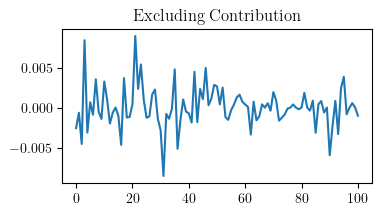

In [17]:
fig, ax = plt.subplots(figsize=(4,2))
#ax.plot(np.arange(len(vdw_ene_diff)),vdw_ene_diff)
ax.plot(np.arange(len(excluding_ene_diff)),excluding_ene_diff)
ax.set_title('Excluding Contribution')

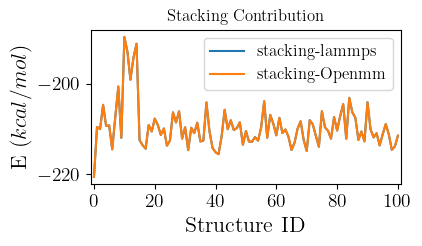

In [18]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(np.arange(d_lmp_decomp.shape[0]), d_lmp_decomp[:,1], label='stacking-lammps')
ax.plot(np.arange(d_lmp_decomp.shape[0]), enetest[:,3], label='stacking-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

ax.set_title('Stacking Contribution')

stacking_ene_diff = d_lmp_decomp[:,1] - enetest[:,3]

Text(0.5, 1.0, 'Stacking Contribution')

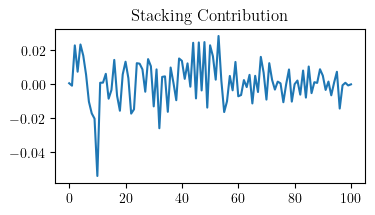

In [19]:
fig, ax = plt.subplots(figsize=(4,2))
#ax.plot(np.arange(len(vdw_ene_diff)),vdw_ene_diff)
ax.plot(np.arange(len(stacking_ene_diff)),stacking_ene_diff)
ax.set_title('Stacking Contribution')

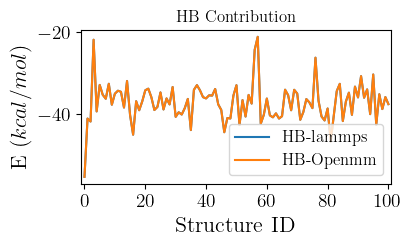

In [20]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(np.arange(d_lmp_decomp.shape[0]), d_lmp_decomp[:,2], label='HB-lammps')
ax.plot(np.arange(d_lmp_decomp.shape[0]), enetest[:,4], label='HB-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

ax.set_title('HB Contribution')

HB_ene_diff = d_lmp_decomp[:,2] - enetest[:,4]

Text(0.5, 1.0, 'HB Contribution')

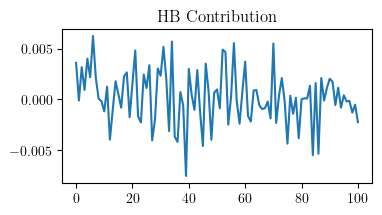

In [21]:
fig, ax = plt.subplots(figsize=(4,2))
#ax.plot(np.arange(len(vdw_ene_diff)),vdw_ene_diff)
ax.plot(np.arange(len(HB_ene_diff)),HB_ene_diff)
ax.set_title('HB Contribution')

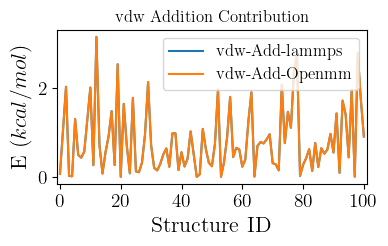

In [22]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(np.arange(d_lmp_decomp.shape[0]), d_lmp_decomp[:,4], label='vdw-Add-lammps')
ax.plot(np.arange(d_lmp_decomp.shape[0]), enetest[:,7], label='vdw-Add-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

ax.set_title('vdw Addition Contribution')

vdw_add_ene_diff = d_lmp_decomp[:,4] - enetest[:,7]

Text(0.5, 1.0, 'vdW Addition Contribution')

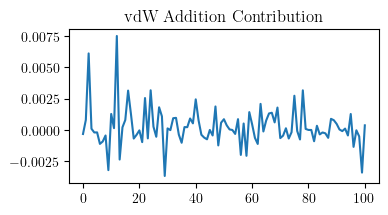

In [23]:
fig, ax = plt.subplots(figsize=(4,2))
#ax.plot(np.arange(len(vdw_ene_diff)),vdw_ene_diff)
ax.plot(np.arange(len(vdw_add_ene_diff)),vdw_add_ene_diff)
ax.set_title('vdW Addition Contribution')